# SME Financial Pipeline: Invoices Late Payment Classification (df3)
**Classification Task on `is_late` (0 = On-Time, 1 = Late Payment)**
تحليل ونمذجة تصنيف الفواتير للتنبؤ باحتمالية تأخر السداد ومنع التعثر المالي.


In [2]:
# ========== Standard Library & Data Handling Imports ==========
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import pickle
import os

# ========== Scikit-learn Tools for Classification ==========
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             classification_report, RocCurveDisplay)


In [3]:
# Load the datasets
payments_path = 'synthetic_sme_payments.csv'
cash_flow_path = 'synthetic_sme_daily_cash_flow.csv'
expenses_path = 'synthetic_sme_expenses.csv'
invoices_path = 'synthetic_sme_invoices.csv'

df_payments = pd.read_csv(payments_path)
df_cash_flow = pd.read_csv(cash_flow_path)
df_expenses = pd.read_csv(expenses_path)
df_invoices = pd.read_csv(invoices_path)

# Assign datasets
df = df_payments
df1 = df_cash_flow
df2 = df_expenses
df3 = df_invoices


In [4]:
# Display preview of df3 (Invoices)
print("Invoices (df3) Preview:")
df3.head()


Invoices (df3) Preview:


,invoice_id,business_id,invoice_date,due_date,paid_date,customer_id,invoice_amount_egp,amount_paid_egp,payment_delay_days,is_late,status
0,INV_SME_001_20230101_0000,SME_001,2023-01-01,2023-01-31,2023-01-31,CUST_045,3622.22,3536.77,0,0,paid
1,INV_SME_001_20230102_0001,SME_001,2023-01-02,2023-02-01,2023-02-08,CUST_021,7015.34,6580.53,7,1,paid
2,INV_SME_001_20230103_0002,SME_001,2023-01-03,2023-02-17,2023-02-17,CUST_023,10360.79,9817.09,0,0,paid
3,INV_SME_001_20230104_0003,SME_001,2023-01-04,2023-02-03,2023-02-03,CUST_012,9255.20,8887.91,0,0,paid
4,INV_SME_001_20230105_0004,SME_001,2023-01-05,2023-02-19,2023-02-19,CUST_150,3950.01,3874.79,0,0,paid


In [5]:
# Summary statistics of df3
df3.describe().T


,count,mean,std,min,25%,50%,75%,max
invoice_amount_egp,8768.0,4153.219959,2827.664175,306.92,2094.8400,3239.795,5583.8525,21590.77
amount_paid_egp,8768.0,3985.166253,2718.640654,0.00,2012.3025,3098.285,5361.8250,21364.94
payment_delay_days,8768.0,3.805771,11.074178,0.00,0.0000,0.000,0.0000,60.00
is_late,8768.0,0.192518,0.394300,0.00,0.0000,0.000,0.0000,1.00


In [6]:
# Dataset shape
print("df3 Shape:", df3.shape)


df3 Shape: (8768, 11)


In [7]:
# Value counts of target: is_late (Classification Target)
print("Late Invoices Count (0 = On-Time, 1 = Late):")
display(df3['is_late'].value_counts())
print("\nLate Invoices Percentage:")
display(df3['is_late'].value_counts(normalize=True) * 100)


Late Invoices Count (0 = On-Time, 1 = Late):


is_late
0    7080
1    1688
Name: count, dtype: int64


Late Invoices Percentage:


is_late
0    80.748175
1    19.251825
Name: proportion, dtype: float64

In [8]:
# Check for missing values and duplicates
print("Missing values in df3:")
display(df3.isnull().sum())
print(f"\nDuplicated records: {df3.duplicated().sum()}")


Missing values in df3:


invoice_id            0
business_id           0
invoice_date          0
due_date              0
paid_date             4
customer_id           0
invoice_amount_egp    0
amount_paid_egp       0
payment_delay_days    0
is_late               0
status                0
dtype: int64


Duplicated records: 0


In [9]:
# Unique counts of business and customers
print("Unique Businesses:", df3['business_id'].nunique())
print("Unique Customers:", df3['customer_id'].nunique())


Unique Businesses: 8
Unique Customers: 150


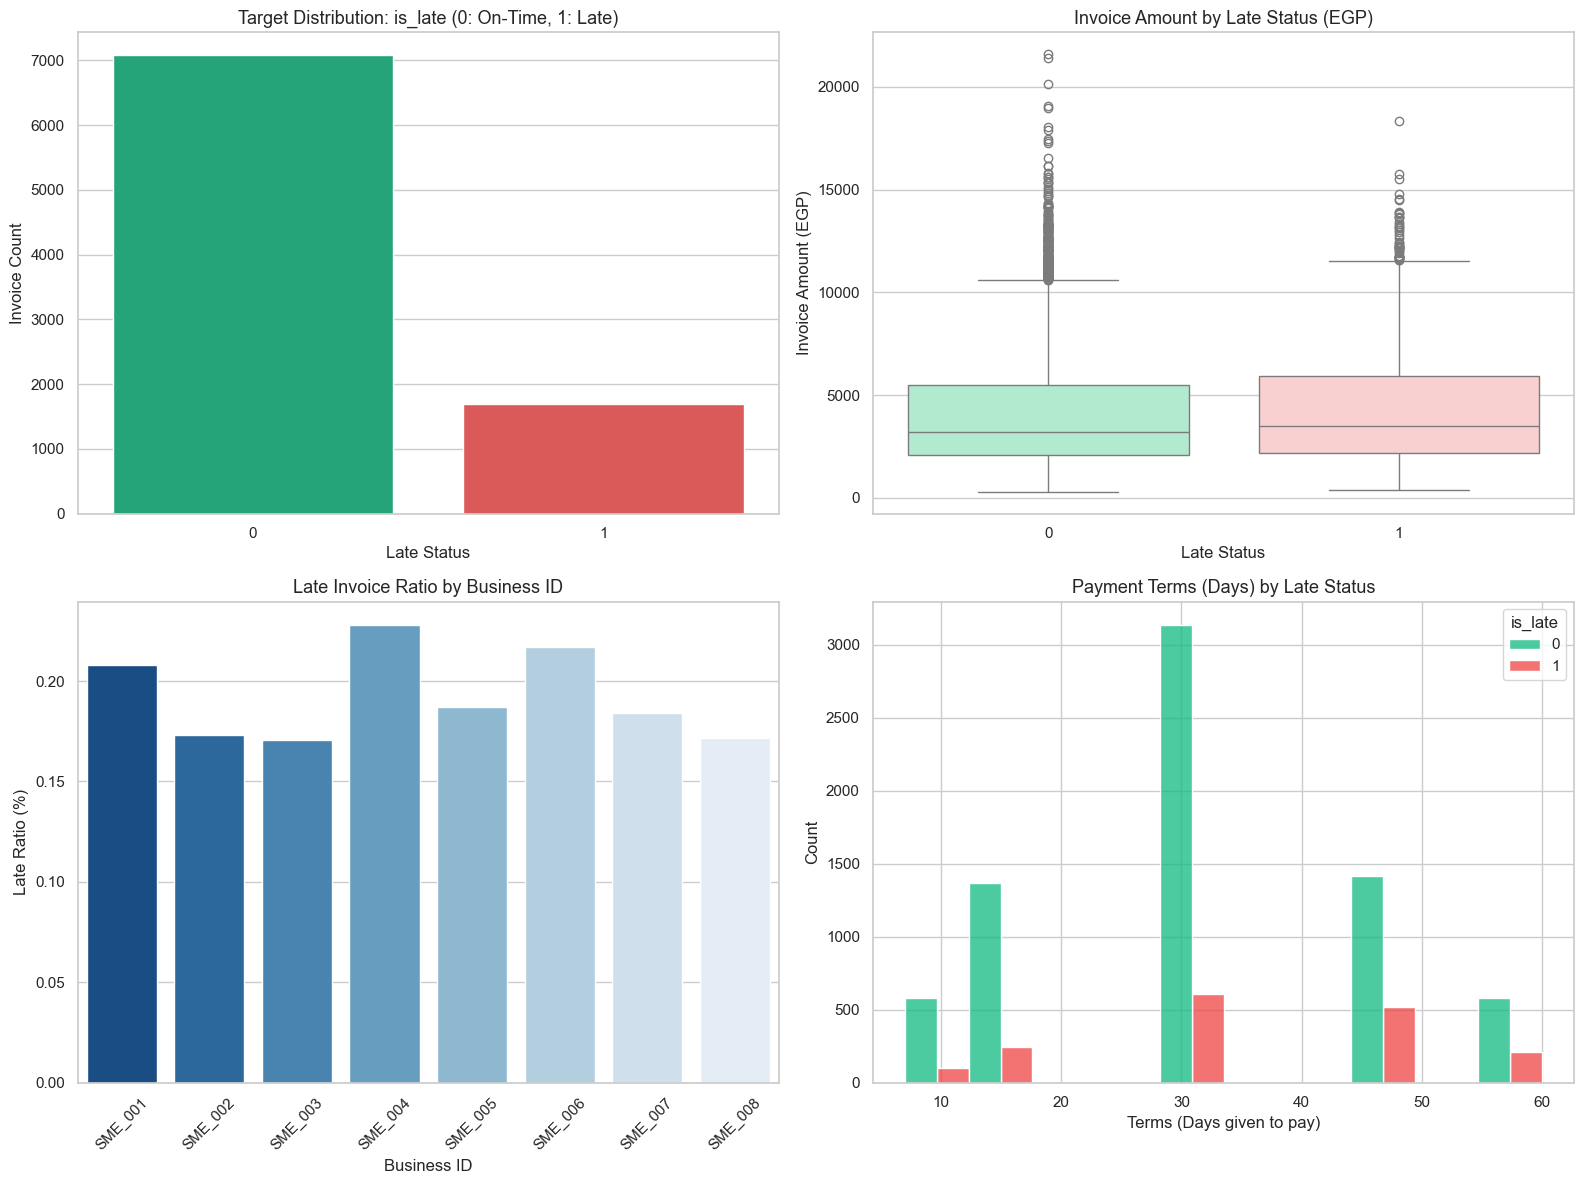

In [10]:
# ========== Visualizations for df3 (Invoices Classification) ==========
df3_viz = df3.copy()
df3_viz['invoice_date'] = pd.to_datetime(df3_viz['invoice_date'])
df3_viz['due_date'] = pd.to_datetime(df3_viz['due_date'])
df3_viz['terms_days'] = (df3_viz['due_date'] - df3_viz['invoice_date']).dt.days

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Target Distribution (is_late)
sns.countplot(
    ax=axes[0, 0],
    data=df3_viz,
    x='is_late',
    palette=['#10B981', '#EF4444']
)
axes[0, 0].set_title('Target Distribution: is_late (0: On-Time, 1: Late)', fontsize=13)
axes[0, 0].set_xlabel('Late Status')
axes[0, 0].set_ylabel('Invoice Count')

# 2. Invoice Amount Distribution by Late Status
sns.boxplot(
    ax=axes[0, 1],
    data=df3_viz,
    x='is_late',
    y='invoice_amount_egp',
    palette=['#A7F3D0', '#FECACA']
)
axes[0, 1].set_title('Invoice Amount by Late Status (EGP)', fontsize=13)
axes[0, 1].set_xlabel('Late Status')
axes[0, 1].set_ylabel('Invoice Amount (EGP)')

# 3. Late Ratio by Business ID
late_by_bus = df3_viz.groupby('business_id')['is_late'].mean().reset_index()
sns.barplot(
    ax=axes[1, 0],
    data=late_by_bus,
    x='business_id',
    y='is_late',
    palette='Blues_r'
)
axes[1, 0].set_title('Late Invoice Ratio by Business ID', fontsize=13)
axes[1, 0].set_xlabel('Business ID')
axes[1, 0].set_ylabel('Late Ratio (%)')
axes[1, 0].tick_params(axis='x', rotation=45)

# 4. Payment Terms (terms_days) vs Late Status
sns.histplot(
    ax=axes[1, 1],
    data=df3_viz,
    x='terms_days',
    hue='is_late',
    multiple='dodge',
    palette=['#10B981', '#EF4444'],
    bins=10
)
axes[1, 1].set_title('Payment Terms (Days) by Late Status', fontsize=13)
axes[1, 1].set_xlabel('Terms (Days given to pay)')
axes[1, 1].set_ylabel('Count')

plt.tight_layout()
plt.show()


In [11]:
# ========== Preprocessing & Feature Engineering ==========
df3_encoded = df3.copy()

# Date feature extraction & terms calculation
df3_encoded['invoice_date'] = pd.to_datetime(df3_encoded['invoice_date'])
df3_encoded['due_date'] = pd.to_datetime(df3_encoded['due_date'])
df3_encoded['terms_days'] = (df3_encoded['due_date'] - df3_encoded['invoice_date']).dt.days

df3_encoded['year'] = df3_encoded['invoice_date'].dt.year
df3_encoded['month'] = df3_encoded['invoice_date'].dt.month
df3_encoded['day'] = df3_encoded['invoice_date'].dt.day
df3_encoded['day_of_week'] = df3_encoded['invoice_date'].dt.dayofweek

# Target leakage columns prevention:
# paid_date, amount_paid_egp, payment_delay_days, status are post-event outcomes!
# When an invoice is issued, these are unknown.
leakage_cols = ['invoice_id', 'invoice_date', 'due_date', 'paid_date',
                'amount_paid_egp', 'payment_delay_days', 'status']
df3_encoded.drop(columns=leakage_cols, inplace=True)

# Encode categorical variables
le_bus = LabelEncoder()
df3_encoded['business_id'] = le_bus.fit_transform(df3_encoded['business_id'])

le_cust = LabelEncoder()
df3_encoded['customer_id'] = le_cust.fit_transform(df3_encoded['customer_id'])

print("Clean Encoded df3 Preview:")
df3_encoded.head()


Clean Encoded df3 Preview:


,business_id,customer_id,invoice_amount_egp,is_late,terms_days,year,month,day,day_of_week
0,0,44,3622.22,0,30,2023,1,1,6
1,0,20,7015.34,1,30,2023,1,2,0
2,0,22,10360.79,0,45,2023,1,3,1
3,0,11,9255.20,0,30,2023,1,4,2
4,0,149,3950.01,0,45,2023,1,5,3


In [12]:
# Separate Features (X) and Target (y: is_late)
X = df3_encoded.drop(columns=['is_late'])
y = df3_encoded['is_late']

# Stratified Train/Test Split (80/20) to maintain class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")
print(f"Train late ratio: {y_train.mean():.4f}, Test late ratio: {y_test.mean():.4f}")


X_train shape: (7014, 8), X_test shape: (1754, 8)
Train late ratio: 0.1925, Test late ratio: 0.1927


In [13]:
# Feature Scaling using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

print("Data Scaling Complete!")
X_train_scaled_df.head()


Data Scaling Complete!


,business_id,customer_id,invoice_amount_egp,terms_days,year,month,day,day_of_week
0,-0.209672,-0.710294,3.316194,1.942123,1.222254,0.716190,-1.108385,0.999092
1,-1.512663,-0.571881,0.329024,0.929065,1.222254,1.297059,1.623523,1.499029
2,-1.512663,-0.456536,2.069382,-1.164588,-1.238391,0.425755,-1.336044,0.499154
3,-1.078333,0.397012,-0.693901,0.929065,-0.008069,-1.316852,0.599057,-0.500722
4,0.658988,1.181354,1.565569,-1.164588,-0.008069,1.587493,1.623523,-1.500597


In [14]:
# ========== Classification Models Training & Comparison ==========
models = {
    'Logistic Regression': LogisticRegression(random_state=42, class_weight='balanced'),
    'Decision Tree': DecisionTreeClassifier(random_state=42, max_depth=6),
    'Random Forest': RandomForestClassifier(random_state=42, n_estimators=100, class_weight='balanced'),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss')
}

results = {}
print("=== Training Classification Models on is_late ===\n")

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    probs = model.predict_proba(X_test_scaled)[:, 1] if hasattr(model, 'predict_proba') else predictions

    acc = accuracy_score(y_test, predictions)
    prec = precision_score(y_test, predictions, zero_division=0)
    rec = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    auc = roc_auc_score(y_test, probs)

    results[name] = {
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1 Score': f1,
        'ROC AUC': auc
    }

results_df = pd.DataFrame(results).T
print("\n=== Classification Comparison Results ===")
display(results_df.sort_values(by='ROC AUC', ascending=False))


=== Training Classification Models on is_late ===

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Gradient Boosting...
Training XGBoost...

=== Classification Comparison Results ===


,Accuracy,Precision,Recall,F1 Score,ROC AUC
Gradient Boosting,0.805017,0.000000,0.000000,0.000000,0.599852
Random Forest,0.805017,0.250000,0.005917,0.011561,0.596080
Logistic Regression,0.575827,0.241730,0.562130,0.338078,0.587140
Decision Tree,0.797035,0.200000,0.017751,0.032609,0.557493
XGBoost,0.785633,0.284091,0.073964,0.117371,0.545248


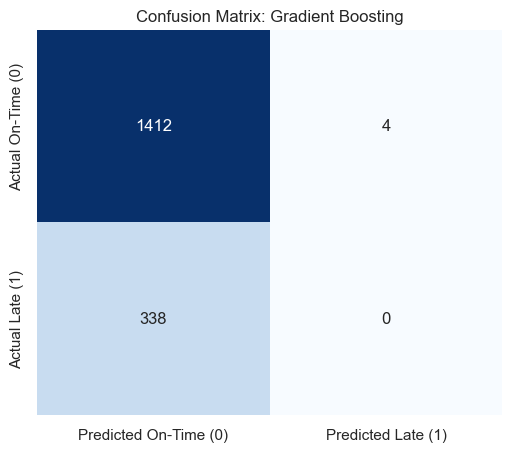

Classification Report (Gradient Boosting):

              precision    recall  f1-score   support

           0       0.81      1.00      0.89      1416
           1       0.00      0.00      0.00       338

    accuracy                           0.81      1754
   macro avg       0.40      0.50      0.45      1754
weighted avg       0.65      0.81      0.72      1754



In [15]:
# Display Confusion Matrix for the Best ROC-AUC Model
best_model_name = results_df['ROC AUC'].idxmax()
best_clf = models[best_model_name]
preds_best = best_clf.predict(X_test_scaled)

cm = confusion_matrix(y_test, preds_best)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Predicted On-Time (0)', 'Predicted Late (1)'],
            yticklabels=['Actual On-Time (0)', 'Actual Late (1)'])
plt.title(f'Confusion Matrix: {best_model_name}')
plt.show()

print(f"Classification Report ({best_model_name}):\n")
print(classification_report(y_test, preds_best, zero_division=0))


In [16]:
# ========== Hyperparameter Fine-Tuning ==========
print("=== Hyperparameter Fine-Tuning Gradient Boosting ===\n")

gb_param_dist = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 4, 5],
    'learning_rate': [0.03, 0.05, 0.1]
}

gb_grid = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=gb_param_dist,
    n_iter=5,
    scoring='roc_auc',
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=1
)
gb_grid.fit(X_train_scaled, y_train)

best_gb = gb_grid.best_estimator_
gb_probs = best_gb.predict_proba(X_test_scaled)[:, 1]
print(f"Best Params: {gb_grid.best_params_}")
print(f"Fine-tuned ROC-AUC: {roc_auc_score(y_test, gb_probs):.4f}")


=== Hyperparameter Fine-Tuning Gradient Boosting ===

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Params: {'n_estimators': 50, 'max_depth': 3, 'learning_rate': 0.03}
Fine-tuned ROC-AUC: 0.5977


In [17]:
# ========== Save Classification Model and Scaler ==========
with open('best_inv_model.pkl', 'wb') as f:
    pickle.dump(best_gb, f)

with open('scaler_inv.pkl', 'wb') as f:
    pickle.dump(scaler, f)

with open('le_inv_bus.pkl', 'wb') as f:
    pickle.dump(le_bus, f)

with open('le_inv_cust.pkl', 'wb') as f:
    pickle.dump(le_cust, f)

print("Saved 'best_inv_model.pkl', 'scaler_inv.pkl', and Encoders successfully!")


Saved 'best_inv_model.pkl', 'scaler_inv.pkl', and Encoders successfully!


### تجربة التنبؤ بعينة واختبار الاحتمالية (Probability & Risk Score):


In [18]:
# Test Sample Prediction
sample_input = X_test.iloc[0:1]
scaled_sample = scaler.transform(sample_input)
pred_class = best_gb.predict(scaled_sample)[0]
pred_prob = best_gb.predict_proba(scaled_sample)[0][1]

print(f"Predicted Class: {pred_class} ({'Late' if pred_class == 1 else 'On-Time'})")
print(f"Late Probability: {pred_prob * 100:.2f}%")
print(f"Actual Value: {y_test.iloc[0]} ({'Late' if y_test.iloc[0] == 1 else 'On-Time'})")


Predicted Class: 0 (On-Time)
Late Probability: 17.68%
Actual Value: 0 (On-Time)
